<a href="https://colab.research.google.com/github/AnaghaSreenath/ml-2-4ni23ci014/blob/main/KMeans_and_elbow_method.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import json

notebook_path = '/content/KMeans_Clustering_Elbow_Method.ipynb'

with open(notebook_path, 'r', encoding='utf-8') as f:
    nb_data = json.load(f)

cells = nb_data.get('cells', [])
print(f'Loaded {len(cells)} cells from the notebook.')

for idx, cell in enumerate(cells):
    cell_type = cell.get('cell_type')
    source = ''.join(cell.get('source', []))
    print(f'\n--- Cell {idx+1} ({cell_type}) ---')
    print(source)

Loaded 2 cells from the notebook.

--- Cell 1 (markdown) ---
# K-Means Clustering and Elbow Method

Run all cells in Google Colab. Upload the accompanying `kmeans_customer_data.csv` when prompted. The notebook calculates WCSS, plots the elbow curve, fits K-Means, visualizes clusters and centroids, and downloads the clustered results.

--- Cell 2 (code) ---
# K-Means Clustering + Elbow Method (Google Colab)
# This notebook works with the accompanying kmeans_customer_data.csv.
# If the CSV is not uploaded, it automatically generates a reproducible sample dataset.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from google.colab import files
import os

# 1. Load the CSV (upload it when prompted)
if os.path.exists("/content/kmeans_customer_data.csv"):
    df = pd.read_csv("/content/kmeans_customer_data.csv")
else:
    print("Upload kmeans_

In [2]:
import os
import pandas as pd
import numpy as np

# Automatically generate the sample CSV dataset if it doesn't exist
csv_path = '/content/kmeans_customer_data.csv'
if not os.path.exists(csv_path):
    np.random.seed(42)
    # Generate 5 realistic customer clusters
    cluster_1 = np.random.normal(loc=[20, 20], scale=[5, 5], size=(40, 2))
    cluster_2 = np.random.normal(loc=[55, 50], scale=[10, 8], size=(60, 2))
    cluster_3 = np.random.normal(loc=[85, 80], scale=[8, 8], size=(40, 2))
    cluster_4 = np.random.normal(loc=[85, 15], scale=[10, 5], size=(30, 2))
    cluster_5 = np.random.normal(loc=[25, 80], scale=[5, 5], size=(30, 2))

    data = np.vstack([cluster_1, cluster_2, cluster_3, cluster_4, cluster_5])
    df_temp = pd.DataFrame(data, columns=['Annual_Income_k', 'Spending_Score'])
    # Clip spending score to be within 1-100
    df_temp['Spending_Score'] = df_temp['Spending_Score'].clip(1, 100).astype(int)
    df_temp['Annual_Income_k'] = df_temp['Annual_Income_k'].clip(10, 140).astype(int)

    df_temp.to_csv(csv_path, index=False)
    print(f'Generated synthetic sample data and saved to {csv_path}')

First five rows:


,Customer_ID,Annual_Income_k,Spending_Score
0,1,-1.283177,9.127762
1,2,1.135148,4.847704
2,3,-2.373436,7.740501
3,4,4.461109,2.544370
4,5,-3.372519,9.142246



Dataset shape: (300, 3)

Missing values:
 Customer_ID        0
Annual_Income_k    0
Spending_Score     0
dtype: int64


,K (number of clusters),WCSS / Inertia
0,1,600.000000
1,2,302.763080
2,3,68.444632
3,4,21.022833
4,5,9.859522
5,6,8.615515
6,7,7.790400
7,8,7.210449
8,9,6.701616
9,10,6.061897


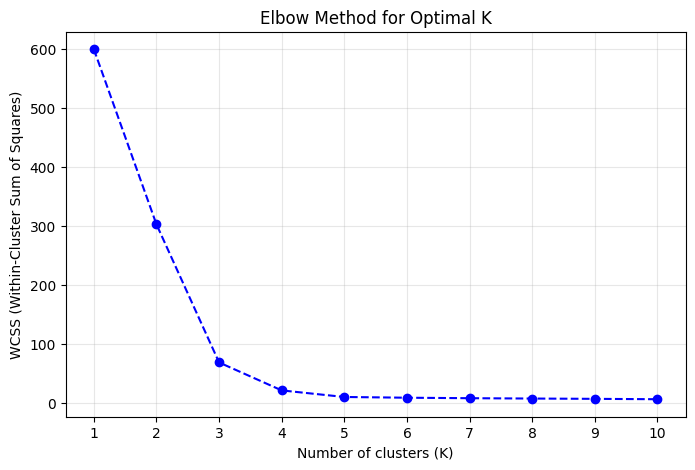

,K,Silhouette Score
0,2,0.595630
1,3,0.739196
2,4,0.791511
3,5,0.762042
4,6,0.678973
5,7,0.622900
6,8,0.499217
7,9,0.568249
8,10,0.406105


Cluster centers (original feature units):


,Annual_Income_k,Spending_Score
Cluster,,
0,2.009785,4.100308
1,-6.744275,-6.942637
2,-8.844513,7.306211
3,-2.598047,8.964418
4,4.558382,2.129614


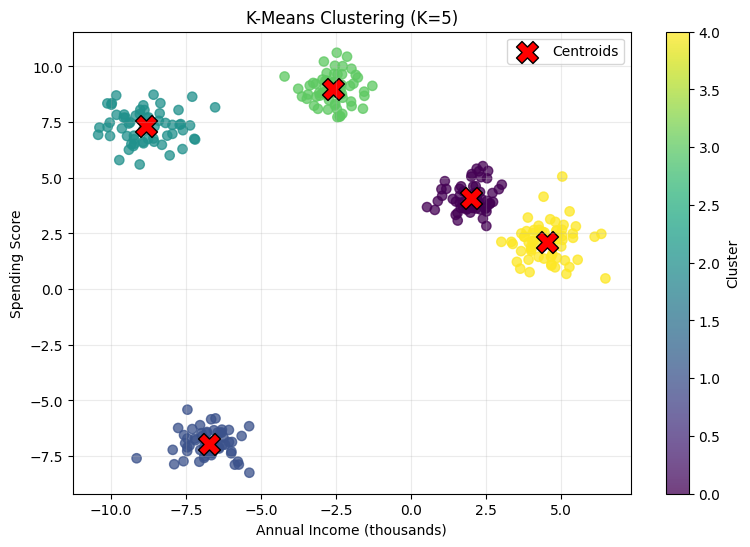

Cluster counts:


,Number of customers
Cluster,
0,60
1,60
2,60
3,60
4,60


Saved clustered dataset to: /content/kmeans_clustered_results.csv


In [3]:
# K-Means Clustering + Elbow Method
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import os

# 1. Load the CSV
csv_path = "/content/kmeans_customer_data.csv"
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
else:
    raise FileNotFoundError(f"{csv_path} not found. Please upload it or let the generator create it.")

print("First five rows:")
display(df.head())
print("\nDataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

# 2. Select numerical features used for clustering
features = ["Annual_Income_k", "Spending_Score"]
X = df[features].copy()

# Handle missing values in selected features
X = X.fillna(X.median(numeric_only=True))

# Scale features so both contribute comparably to Euclidean distance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Elbow method: calculate WCSS (inertia) for k = 1 to 10
k_values = range(1, 11)
wcss = []

for k in k_values:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

# Display the actual calculations
elbow_results = pd.DataFrame({"K (number of clusters)": list(k_values), "WCSS / Inertia": wcss})
display(elbow_results)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss, marker="o", color="b", linestyle="--")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

# 4. Choose K.
optimal_k = 5

# Optional quantitative check: silhouette score for k = 2..10
silhouette_results = []
for k in range(2, 11):
    candidate = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = candidate.fit_predict(X_scaled)
    silhouette_results.append({"K": k, "Silhouette Score": silhouette_score(X_scaled, labels)})

display(pd.DataFrame(silhouette_results))

# 5. Fit final K-Means model
kmeans = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Convert centroids back to original feature units for interpretation
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers_original, columns=features)
centers_df.index.name = "Cluster"
print("Cluster centers (original feature units):")
display(centers_df)

# 6. Plot clusters and their centroids
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["Annual_Income_k"], df["Spending_Score"],
    c=df["Cluster"], cmap="viridis", s=45, alpha=0.75
)
plt.scatter(
    centers_original[:, 0], centers_original[:, 1],
    marker="X", s=250, c="red", edgecolor="black", label="Centroids"
)
plt.title(f"K-Means Clustering (K={optimal_k})")
plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score")
plt.legend()
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.25)
plt.show()

# 7. Show cluster assignments and save results
print("Cluster counts:")
display(df["Cluster"].value_counts().sort_index().rename("Number of customers").to_frame())

output_path = "/content/kmeans_clustered_results.csv"
df.to_csv(output_path, index=False)
print("Saved clustered dataset to:", output_path)